In [1]:
# Import libraries
import mdtraj as mdt
from MDAnalysisData import datasets
import matplotlib.pyplot as plt
import seaborn as sns
import saencode

#### 1. Load trajectory

Note: The `MDAnalysisData.adk_equilibrium` module contains a 1-µs equilibrium MD trajectory of a globular protein with all solvent removed.

In [2]:
# Fetch an example molecular dynamics trajectory
adk = datasets.fetch_adk_equilibrium()

In [3]:
# Pre-process molecular dynamics trajectory and extract only CA
top = mdt.load_psf(adk["topology"])
ca_atoms = top.select("name CA")
traj = mdt.load_dcd(
    filename=adk["trajectory"], 
    top=adk["topology"], 
    atom_indices=ca_atoms
    )

In [4]:
# Check trajectory
traj

<mdtraj.Trajectory with 4187 frames, 214 atoms, 214 residues, and unitcells at 0x7e100c3c2010>

#### 2. Encode trajectory using M32K25 alphabet


In [5]:
# Encode a trajectory
encoding = saencode.encode_traj(traj.xyz)

100%|█████████████████████████████████████████████████████████████████████████████████| 4187/4187 [12:29<00:00,  5.59it/s]


In [6]:
# Check encoding matrix
encoding

array([['B', 'G', 'A', ..., 'U', 'U', 'W'],
       ['E', 'G', 'G', ..., 'U', 'U', 'U'],
       ['E', 'D', 'I', ..., 'U', 'U', 'U'],
       ...,
       ['E', 'G', 'A', ..., 'U', 'W', 'R'],
       ['E', 'G', 'G', ..., 'U', 'U', 'V'],
       ['E', 'G', 'A', ..., 'U', 'U', 'R']],
      shape=(4187, 211), dtype='<U1')

#### 3. Compute normalized mutual information per each trajectory block and their similarity

In [7]:
# Compute normalized mutual information for a given number of trajectory block
traj_nmi_blocks = saencode.compute_nMI_for_traj_blocks(encoding, number_of_blocks=50)

100%|█████████████████████████████████████████████████████████████████████████████████████| 50/50 [04:17<00:00,  5.16s/it]


In [8]:
# Compute similarity (matrix overlap) between two normalized mutual information matrices
similarity = saencode.compute_matrix_overlap(traj_nmi_blocks)

/home/kausasm/github/SAEncode/saencode/matrix_overlap.py:58: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  diff = sqrtm(A) - sqrtm(B)
/home/kausasm/github/SAEncode/saencode/matrix_overlap.py:84: ComplexWarning: Casting complex values to real discards the imaginary part
  overlap[i, j] = matrix_overlap(nmi_blocks[i], nmi_blocks[j])


#### 4. Visualized per block similarity

<Axes: >

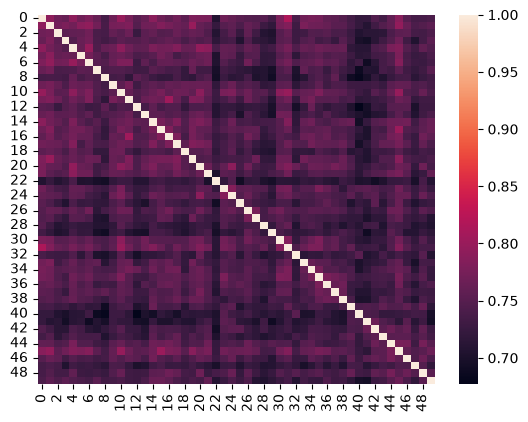

In [10]:
# Plot similarity matrix between blocks (unclustered)
sns.heatmap(similarity)

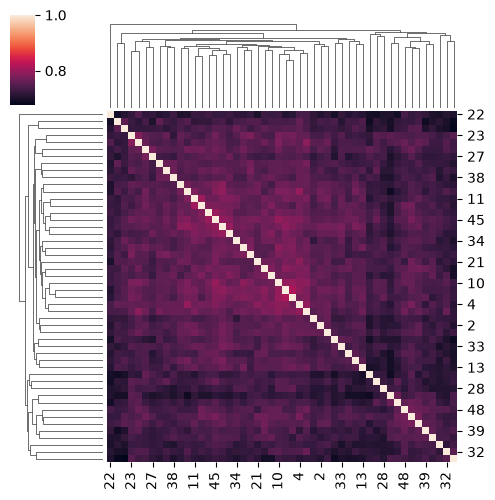

In [15]:
# Plot similarity matrix between blocks (clustered)
sns.clustermap(similarity, figsize=(5, 5))